<a href="https://colab.research.google.com/github/Jawad69Ab/Jawad_C_exo/blob/main/TD_seance1_etudiants_1(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI4SEC · Séance 1 — TD : classifier des flux réseau synthétiques

**Mission du binôme** : construire un classifieur CART, le comparer à une baseline, mesurer ses erreurs, choisir un seuil et tester une dérive légitime.

Règles : exécuter les cellules **dans l'ordre** (Maj + Entrée). En cas de doute : *Redémarrer et tout exécuter*. Après chaque cellule, écrire **une phrase d'interprétation**. Jeu synthétique : aucun scan, aucune cible réelle.

## Test de l'environnement
Vérifie que les quatre bibliothèques sont disponibles. Si un import échoue : Colab, ou `%pip install numpy pandas matplotlib scikit-learn` puis redémarrer le noyau.

In [ ]:
import sys, numpy, pandas, matplotlib, sklearn
print("Python      :", sys.version.split()[0])
print("numpy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("scikit-learn:", sklearn.__version__)
print("Environnement prêt")

Python      : 3.13.18
numpy       : 2.4.6
pandas      : 2.2.3
scikit-learn: 1.6.1
Environnement prêt


## Cellule 0 — Importer les bibliothèques
Aucune sortie attendue : c'est bon signe.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    confusion_matrix, classification_report,
    accuracy_score, balanced_accuracy_score,
    precision_score, recall_score, f1_score,
    matthews_corrcoef
)

## Cellule 1A — Générer quatre variables de flux
La graine 42 garantit que tout le monde obtient les mêmes données.

In [ ]:
rng = np.random.default_rng(42)
n = 4000

df = pd.DataFrame({
    "duration_s": rng.gamma(2, 4, n),
    "bytes_out": rng.lognormal(7.4, 1.0, n),
    "bytes_in": rng.lognormal(7.0, 0.9, n),
    "destinations": rng.poisson(3, n) + 1,
})
df.head()

,duration_s,bytes_out,bytes_in,destinations
0,8.367269,4460.414154,1255.674717,4
1,11.341382,2378.721000,347.736476,2
2,7.348862,3952.871833,1208.120263,5
3,6.580282,2028.606198,11498.462452,6
4,12.317021,2850.913954,4824.222179,3


**Interprétation du binôme :** On a 4000 flux simulés décrits par 4 variables (durée, octets sortants, octets entrants, nb de destinations), avec des valeurs plausibles (quelques secondes, quelques milliers d'octets).

## Cellule 1B — Créer le label `attack`
⚠️ Ne relancez pas cette cellule seule : relancez 1A puis 1B.

In [ ]:
signal = (
    (df["bytes_out"] > 9000)
    & (df["duration_s"] < 8)
)

df["attack"] = (
    signal & (rng.random(n) > 0.18)
).astype(int)

extra = rng.choice(n, 25, replace=False)
df.loc[extra, "attack"] = 1
print(df.shape)

(4000, 5)


**Interprétation du binôme :** Le label vaut 1 surtout quand bytes_out > 9000 et durée < 8 s (en retirant au hasard ~18 % de ces cas) + 25 attaques ajoutées n'importe où, donc les labels sont volontairement bruités ; on a bien 4000 lignes et 5 colonnes.

### 💾 Point de sauvegarde 1 — Comprendre le tableau
- Que représente une ligne ?
- Quelles sont les quatre variables d'entrée ?
- Quelle est la cible ?
- Que signifient les valeurs 0 et 1 ?

**Réponse du binôme :**
- Une ligne = un flux réseau (une connexion) synthétique.
- Les 4 variables d'entrée : `duration_s`, `bytes_out`, `bytes_in`, `destinations`.
- La cible c'est la colonne `attack`.
- 0 = flux légitime, 1 = flux étiqueté comme attaque.

## Cellule 2 — Inspecter la forme et les colonnes

In [ ]:
print("forme :", df.shape)
print()
print("colonnes :", list(df.columns))
print()
print("types :")
print(df.dtypes)
print()
print("valeurs manquantes :")
print(df.isna().sum())
print()
print("statistiques :")
print(df.describe().round(2))

forme : (4000, 5)

colonnes : ['duration_s', 'bytes_out', 'bytes_in', 'destinations', 'attack']

types :
duration_s      float64
bytes_out       float64
bytes_in        float64
destinations      int64
attack            int64
dtype: object

valeurs manquantes :
duration_s      0
bytes_out       0
bytes_in        0
destinations    0
attack          0
dtype: int64

statistiques :
       duration_s  bytes_out  bytes_in  destinations   attack
count     4000.00    4000.00   4000.00       4000.00  4000.00
mean         8.04    2723.52   1639.04          4.01     0.03
std          5.62    4082.57   1734.00          1.76     0.18
min          0.06      47.98     33.15          1.00     0.00
25%          3.93     826.38    595.97          3.00     0.00
50%          6.80    1591.66   1074.13          4.00     0.00
75%         10.73    3149.24   2007.26          5.00     0.00
max         41.84  103905.95  17864.71         12.00     1.00


**Interprétation du binôme :** Pas de valeurs manquantes et que du numérique ; bytes_out est très étalé (médiane ~1 592 mais max ~103 906) et la moyenne de attack à 0,03 montre déjà que les attaques sont rares.

## Cellule 3 — Mesurer la répartition des classes
Notez les deux nombres.

In [ ]:
counts = df["attack"].value_counts().sort_index()
rates = df["attack"].value_counts(
    normalize=True
).sort_index()

print("comptes :")
print(counts)
print()
print("proportions :")
print(rates.round(4))

comptes :
attack
0    3873
1     127
Name: count, dtype: int64

proportions :
attack
0    0.9682
1    0.0318
Name: proportion, dtype: float64


**Interprétation du binôme :** 3 873 flux légitimes pour 127 attaques, soit seulement 3,18 % d'attaques : le jeu est très déséquilibré.

### 💾 Point de sauvegarde 2 — Le piège de l'accuracy
- Calculez l'accuracy de la prédiction « toujours légitime ».
- Calculez le rappel attaque.
- Pourquoi les deux résultats se contredisent-ils en apparence ?

**Réponse du binôme :**
- Accuracy « toujours légitime » = 3873 / 4000 = 0,968 soit 96,8 %.
- Rappel attaque = 0 / 127 = 0 %, on ne détecte aucune attaque.
- L'accuracy est tirée par la classe majoritaire (96,8 % de légitimes), donc un modèle qui ne fait rien a l'air très bon. Le rappel lui regarde seulement les attaques, et c'est justement ce qu'on cherche à détecter.

## Cellule 4 — Visualiser les distributions
Question : les classes sont-elles parfaitement séparées ?

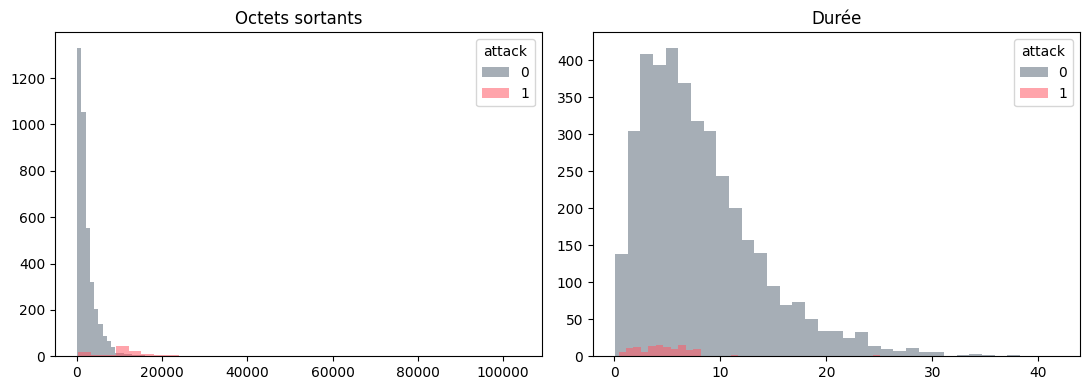

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for label, color in [(0, "#5E6C7B"), (1, "#FF5A66")]:
    part = df[df["attack"] == label]
    axes[0].hist(part["bytes_out"], bins=35,
                 alpha=.55, label=str(label), color=color)
    axes[1].hist(part["duration_s"], bins=35,
                 alpha=.55, label=str(label), color=color)

axes[0].set_title("Octets sortants")
axes[1].set_title("Durée")
for ax in axes: ax.legend(title="attack")
plt.tight_layout()
plt.show()

**Interprétation du binôme :** Non, les classes se chevauchent : les attaques sont plutôt sur les gros bytes_out et les durées courtes, mais on retrouve des attaques au milieu des flux normaux (bruit + les 25 attaques ajoutées au hasard).

## Cellule 5 — Séparer les variables et la cible

In [ ]:
X = df.drop(columns="attack")
y = df["attack"]

print("X :", X.shape)
print("y :", y.shape)
print("variables :", list(X.columns))

X : (4000, 4)
y : (4000,)
variables : ['duration_s', 'bytes_out', 'bytes_in', 'destinations']


**Interprétation du binôme :** X contient les 4 variables d'entrée (4000 × 4) et y la cible (4000 valeurs), on a bien retiré attack de X pour que le modèle ne voie pas la réponse.

## Cellule 6 — Créer le train et le test

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(4), y_test.mean().round(4))

(2800, 4) (1200, 4)
0.0318 0.0317


**Interprétation du binôme :** Découpage 70/30 → 2800 flux en train et 1200 en test, et avec stratify la part d'attaques est quasi la même des deux côtés (3,18 % vs 3,17 %).

## Cellule 7 — Créer une fonction d'évaluation
Aucune sortie attendue : on définit un outil réutilisé ensuite.

In [ ]:
def evaluate(y_true, y_pred):
    return pd.Series({
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, y_pred),
        "precision_attack": precision_score(
            y_true, y_pred, zero_division=0),
        "recall_attack": recall_score(y_true, y_pred),
        "f1_attack": f1_score(y_true, y_pred, zero_division=0),
        "mcc": matthews_corrcoef(y_true, y_pred),
    }).round(3)

## Cellule 8 — Entraîner la baseline
Avant d'exécuter : annoncez l'accuracy et le rappel attaque attendus.

In [ ]:
baseline = DummyClassifier(
    strategy="most_frequent"
)

baseline.fit(X_train, y_train)
pred_base = baseline.predict(X_test)

print(confusion_matrix(y_test, pred_base))
print(evaluate(y_test, pred_base))

[[1162    0]
 [  38    0]]
accuracy             0.968
balanced_accuracy    0.500
precision_attack     0.000
recall_attack        0.000
f1_attack            0.000
mcc                  0.000
dtype: float64


**Interprétation du binôme :** Comme prévu la baseline répond toujours 0 : accuracy 0,968 mais précision, rappel, F1 et MCC à 0 et balanced accuracy à 0,5, donc elle ne détecte strictement rien.

### 💾 Point de sauvegarde 3 — Expliquer la baseline
- Combien de vrais positifs ? De faux négatifs ?
- Pourquoi l'accuracy reste-t-elle élevée ?
- Quelle métrique révèle immédiatement l'échec ?

**Réponse du binôme :**
- 0 vrai positif et 38 faux négatifs : toutes les attaques du test sont ratées.
- L'accuracy reste haute car 1162 flux sur 1200 sont légitimes, donc répondre « légitime » partout donne 1162/1200 = 96,8 %.
- Le rappel attaque (0) montre tout de suite l'échec, comme le MCC à 0 ou la balanced accuracy à 0,5 (= hasard).

## Cellule 9 — Entraîner CART

In [ ]:
cart = DecisionTreeClassifier(
    max_depth=4,
    class_weight="balanced",
    random_state=42
)

cart.fit(X_train, y_train)

print("profondeur :", cart.get_depth())
print("nombre de feuilles :", cart.get_n_leaves())
print("nombre de nœuds :", cart.tree_.node_count)

profondeur : 4
nombre de feuilles : 13
nombre de nœuds : 25


**Interprétation du binôme :** L'arbre est bloqué à 4 niveaux, ce qui donne 13 feuilles et 25 nœuds : il reste assez petit pour être lu et expliqué à quelqu'un.

## Cellule 10 — Prédire puis évaluer CART
Rappel : scikit-learn affiche la matrice dans l'ordre `[[TN, FP], [FN, TP]]`.

In [ ]:
pred_cart = cart.predict(X_test)

print("matrice :")
print(confusion_matrix(y_test, pred_cart))
print()
print("métriques :")
print(evaluate(y_test, pred_cart))
print()
print("rapport :")
print(classification_report(
    y_test, pred_cart, digits=3, zero_division=0
))

matrice :
[[1133   29]
 [   8   30]]

métriques :
accuracy             0.969
balanced_accuracy    0.882
precision_attack     0.508
recall_attack        0.789
f1_attack            0.619
mcc                  0.619
dtype: float64

rapport :
              precision    recall  f1-score   support

           0      0.993     0.975     0.984      1162
           1      0.508     0.789     0.619        38

    accuracy                          0.969      1200
   macro avg      0.751     0.882     0.801      1200
weighted avg      0.978     0.969     0.972      1200



**Interprétation du binôme :** CART trouve 30 attaques sur 38 (rappel 0,789) mais avec 29 fausses alertes (précision 0,508) ; l'accuracy ne bouge presque pas par rapport à la baseline (0,969 vs 0,968) alors que le MCC passe de 0 à 0,619.

### 💾 Calcul à la main — Métriques de CART
- Précision = 30 / (30 + 29) ?
- Rappel = 30 / (30 + 8) ?
- Accuracy = (30 + 1 133) / 1 200 ?
- Nombre total d'alertes ?

**Réponse du binôme :**
- Précision = 30 / 59 ≈ 0,508
- Rappel = 30 / 38 ≈ 0,789
- Accuracy = 1163 / 1200 ≈ 0,969
- Alertes = TP + FP = 30 + 29 = 59

On retombe bien sur les valeurs affichées par scikit-learn.

## Cellule 11 — Visualiser l'arbre
Astuce : ajoutez `max_depth=2` dans `plot_tree` pour ne voir que le haut de l'arbre.

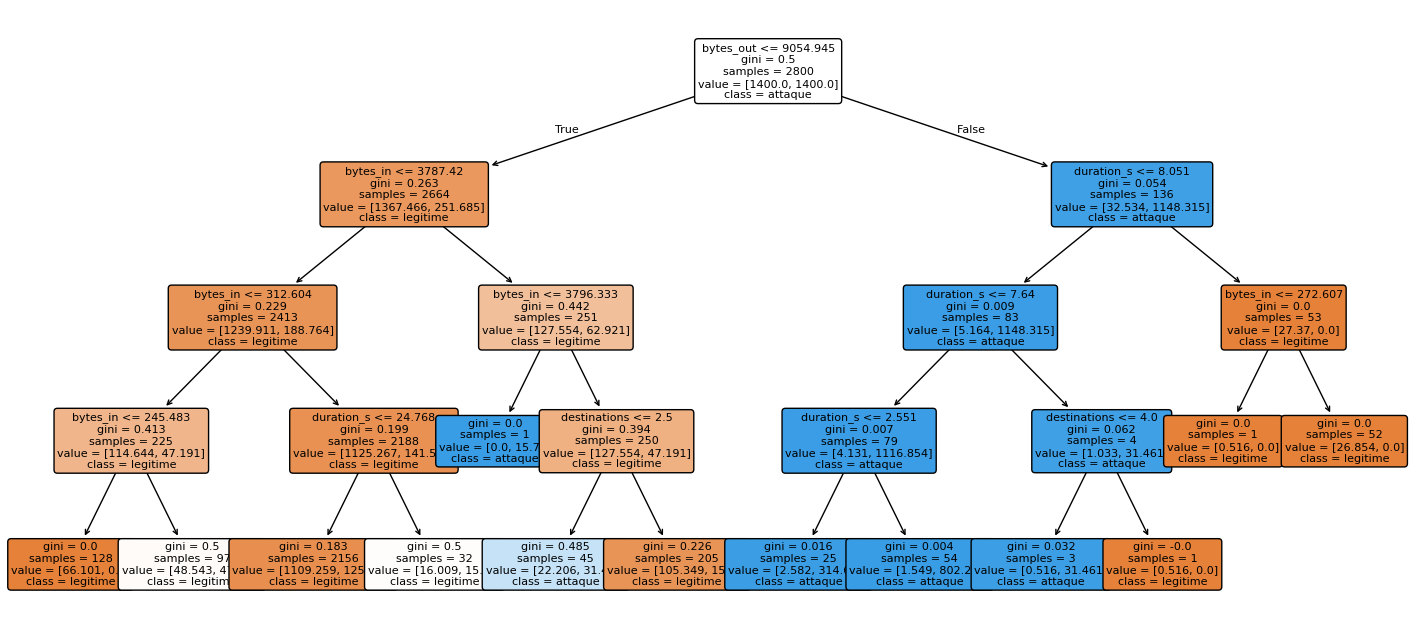

In [ ]:
plt.figure(figsize=(18, 8))
plot_tree(
    cart,
    feature_names=list(X.columns),
    class_names=["legitime", "attaque"],
    filled=True,
    rounded=True,
    fontsize=8
)
plt.show()

**Interprétation du binôme :** Le 1er split se fait sur bytes_out ≈ 9055 puis sur duration_s ≈ 8 s, l'arbre retrouve donc quasiment la règle qui a servi à créer le label ; les branches plus basses (bytes_in, destinations) servent surtout à rattraper le bruit.

## Cellule 12 — Importance des variables

destinations    0.016
bytes_in        0.054
duration_s      0.060
bytes_out       0.870
dtype: float64


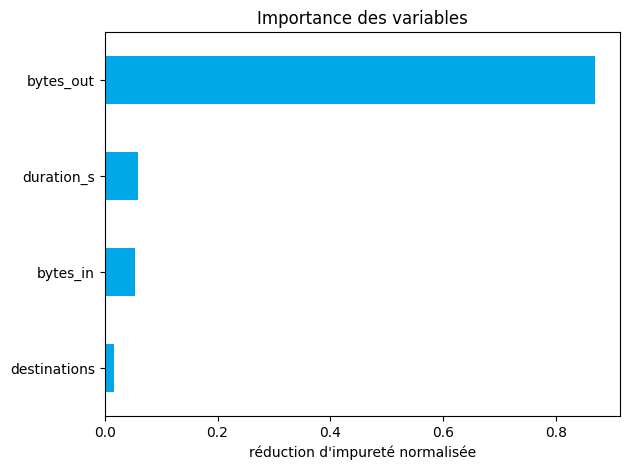

In [ ]:
importance = pd.Series(
    cart.feature_importances_,
    index=X.columns
).sort_values()

print(importance.round(3))

importance.plot.barh(
    color="#00A8E8",
    title="Importance des variables"
)
plt.xlabel("réduction d'impureté normalisée")
plt.tight_layout()
plt.show()

**Interprétation du binôme :** bytes_out écrase tout (0,870) devant duration_s (0,060), bytes_in (0,054) et destinations (0,016) : le modèle dépend presque d'une seule variable, ce qui le rend fragile si elle change.

## Cellule 13 — Tester l'effet de class_weight
Une seule différence entre les deux modèles : la pondération.

In [ ]:
cart_unweighted = DecisionTreeClassifier(
    max_depth=4,
    random_state=42
)
cart_unweighted.fit(X_train, y_train)

pred_unweighted = cart_unweighted.predict(X_test)

comparison = pd.DataFrame({
    "sans_poids": evaluate(y_test, pred_unweighted),
    "balanced": evaluate(y_test, pred_cart),
})
print(comparison)

                   sans_poids  balanced
accuracy                0.987     0.969
balanced_accuracy       0.891     0.882
precision_attack        0.789     0.508
recall_attack           0.789     0.789
f1_attack               0.789     0.619
mcc                     0.783     0.619


**Interprétation du binôme :** Le rappel est identique (0,789) avec ou sans poids, mais sans poids la précision est bien meilleure (0,789 vs 0,508) et le MCC aussi (0,783 vs 0,619) : ici class_weight="balanced" ajoute surtout des fausses alertes (29 au lieu de 8) sans attraper plus d'attaques.

## Cellule 14 — Résultats pour plusieurs seuils
Avant d'exécuter : un seuil plus haut donne-t-il plus ou moins d'alertes ?

In [ ]:
scores = cart.predict_proba(X_test)[:, 1]

rows = []
for threshold in [0.20, 0.35, 0.50, 0.60, 0.80]:
    pred_t = (scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_test, pred_t
    ).ravel()
    rows.append({
        "seuil": threshold,
        "alertes": tp + fp,
        "precision": tp / (tp + fp),
        "rappel": tp / (tp + fn),
    })

thresholds = pd.DataFrame(rows)
print(thresholds.round(3))

   seuil  alertes  precision  rappel
0   0.20      119      0.261   0.816
1   0.35      119      0.261   0.816
2   0.50       59      0.508   0.789
3   0.60       36      0.833   0.789
4   0.80       36      0.833   0.789


**Interprétation du binôme :** Plus le seuil monte, moins il y a d'alertes (119 → 59 → 36) et la précision grimpe de 0,261 à 0,833 alors que le rappel perd seulement 0,816 → 0,789 ; certaines lignes sont identiques car un arbre ne sort que quelques scores possibles (un par feuille).

### 💾 Point de sauvegarde 4 — Choisir un seuil
- Le SOC peut traiter au maximum 60 alertes sur ce lot et veut un rappel aussi élevé que possible.
- Quel seuil choisissez-vous parmi ceux affichés ?
- Justifiez avec au moins trois nombres.

**Réponse du binôme :** On prend le seuil **0,60**.
- 0,20 et 0,35 donnent le meilleur rappel (0,816) mais 119 alertes, c'est 2 fois trop pour le SOC.
- 0,50 et 0,60 ont le même rappel (0,789, soit 30 attaques sur 38).
- À 0,60 on a seulement 36 alertes (précision 0,833) contre 59 à 0,50 (précision 0,508) : même détection, 23 alertes en moins, et on garde de la marge sous les 60 au lieu d'être pile à la limite.

## Cellule 15 — Simuler une dérive légitime
Prévoyez : les faux positifs vont-ils monter, baisser ou rester stables ?

In [ ]:
X_shift = X_test.copy()
changed = X_shift.sample(
    frac=0.25,
    random_state=42
).index

X_shift.loc[changed, "bytes_out"] *= 1.8

scores_shift = cart.predict_proba(X_shift)[:, 1]
pred_shift = (scores_shift >= 0.60).astype(int)

print("avant :")
print(confusion_matrix(y_test, (scores >= 0.60).astype(int)))
print("après :")
print(confusion_matrix(y_test, pred_shift))

avant :
[[1156    6]
 [   8   30]]
après :
[[1138   24]
 [   8   30]]


**Interprétation du binôme :** Les faux positifs passent de 6 à 24 (x4, donc 36 → 54 alertes) alors que les vraies attaques ne changent pas (30 TP, 8 FN) : un simple changement d'usage légitime sur bytes_out suffit à faire exploser les alertes.

## 🏁 Décision finale du binôme (six phrases pour le RSSI)
- Usage autorisé
- Usage refusé
- Seuil retenu
- Preuve chiffrée
- Dérive observée
- Prochaine mesure de suivi et son propriétaire

**Notre décision :**
1. **Usage autorisé** : on autorise le CART (profondeur 4) comme aide au tri des flux pour le SOC, chaque alerte étant revue par un analyste.
2. **Usage refusé** : pas de blocage automatique sans humain, car on rate encore 8 attaques sur 38 (~21 %) et le modèle n'a été testé que sur des données synthétiques (limite 1).
3. **Seuil retenu** : 0,60, qui donne 36 alertes sur 1 200 flux, sous la capacité de 60 alertes du SOC.
4. **Preuve chiffrée** : à ce seuil on a un rappel de 0,789 (30/38) et une précision de 0,833 (30/36), contre un rappel de 0 pour la baseline malgré ses 96,8 % d'accuracy, mais tout ça repose sur seulement 38 attaques dans le test (limite 2).
5. **Dérive observée** : quand 25 % des flux envoient 1,8 fois plus d'octets, les faux positifs passent de 6 à 24 (36 → 54 alertes), parce que le modèle s'appuie à 87 % sur bytes_out (limite 3).
6. **Suivi** : l'équipe SOC (responsable : le lead SOC) suit chaque semaine le nombre d'alertes et le taux de faux positifs, et on relance un entraînement si on dépasse 60 alertes par lot ou si bytes_out dérive.

## Bonus A — Forêt aléatoire (facultatif)
Comparer rappel, précision, MCC et nombre d'alertes avec CART.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    class_weight="balanced",
    random_state=42
)
forest.fit(X_train, y_train)
pred_forest = forest.predict(X_test)

print(confusion_matrix(y_test, pred_forest))
print(evaluate(y_test, pred_forest))

[[1157    5]
 [   8   30]]
accuracy             0.989
balanced_accuracy    0.893
precision_attack     0.857
recall_attack        0.789
f1_attack            0.822
mcc                  0.817
dtype: float64


**Interprétation du binôme :** La forêt a le même rappel que CART (0,789, 30/38) mais seulement 5 faux positifs (35 alertes), donc précision 0,857 et MCC 0,817 contre 0,619 pour CART au seuil 0,5 ; elle est meilleure mais beaucoup moins lisible qu'un arbre de profondeur 4.

## Bonus B — XGBoost (facultatif)
Si xgboost est absent, la cellule l'indique et le TD continue.

In [ ]:
# Extension facultative : le TD continue si xgboost est absent
try:
    from xgboost import XGBClassifier
except Exception as err:   # absent, ou libomp manquant sur macOS
    XGBClassifier = None
    print("Extension ignorée :", type(err).__name__)

if XGBClassifier is not None:
    ratio = (y_train == 0).sum() / (y_train == 1).sum()
    boost = XGBClassifier(
        n_estimators=200, max_depth=4, learning_rate=0.05,
        scale_pos_weight=ratio, random_state=42,
        eval_metric="logloss")
    boost.fit(X_train, y_train)
    print(evaluate(y_test, boost.predict(X_test)))

accuracy             0.984
balanced_accuracy    0.890
precision_attack     0.732
recall_attack        0.789
f1_attack            0.759
mcc                  0.752
dtype: float64


**Interprétation du binôme :** XGBoost garde aussi un rappel de 0,789 avec une précision de 0,732 (≈ 41 alertes) et un MCC de 0,752 : mieux que CART à 0,5 mais un peu en dessous de la forêt, donc pas d'intérêt à complexifier ici.